# 03 - LLM local en few-shot (Ollama) et comparaison finale

Ce notebook évalue la troisième approche : un grand modèle de langage (LLM) exécuté **en local**
via [Ollama](https://ollama.com), utilisé **sans aucun entraînement**. Le modèle reçoit des
instructions et quelques exemples annotés directement dans la requête (*few-shot prompting*),
puis classe chaque critique. Il est ensuite comparé aux deux approches précédentes sur les mêmes
critiques :

| Approche | Entraînement | Notebook |
|---|---|---|
| TF-IDF + régression logistique | quelques minutes, CPU | 01 |
| CamemBERT fine-tuné | plusieurs dizaines de minutes, GPU | 02 |
| LLM local en few-shot | aucun | 03 |

Deux questions guident l'analyse. La première porte sur la précision : un LLM généraliste, sans
entraînement, rattrape-t-il un modèle spécialisé ? La seconde porte sur le coût : à précision
comparable, que représentent la latence, la taille du modèle et le matériel nécessaire ?

### Fonctionnement d'Ollama

Ollama est un serveur qui charge des modèles open source et les expose via une **API HTTP locale**
(par défaut `http://localhost:11434`). Le notebook envoie des requêtes à ce serveur avec la
bibliothèque `requests`, sans dépendre d'un SDK spécifique : le fonctionnement reste visible et
les données ne quittent jamais la machine.

Comme pour le notebook 02, la première exécution se fait avec `SMOKE_TEST = True` sur un très
petit échantillon, pour vérifier que la connexion fonctionne avant tout lancement complet.


## 1. Imports et configuration

In [2]:
# Dépendances : pip install requests transformers datasets scikit-learn scipy pandas matplotlib tqdm joblib

import json
import random
import textwrap
import time
from itertools import combinations
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from datasets import load_dataset
from scipy.stats import binomtest
from sklearn.metrics import f1_score
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

# Périphérique pour CamemBERT (le LLM, lui, est géré par Ollama)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Périphérique pour CamemBERT : {device}")

c:\Users\clement\anaconda3\envs\GPU\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Périphérique pour CamemBERT : cuda


### Paramètres

**Choix du modèle.** Les modèles *instruct* non raisonnants conviennent à cette tâche : ils
répondent directement par un mot. Les modèles à « raisonnement » (qui rédigent une longue
réflexion avant de répondre) ne conviennent pas à une réponse limitée à quelques tokens.
`qwen2.5:7b` offre un bon compromis qualité / taille en français ; `qwen2.5:3b` est l'alternative
si la mémoire vidéo est limitée. Plusieurs modèles peuvent être listés pour comparer l'effet de
la taille.

**Fenêtre de contexte (`NUM_CTX`).** Si le prompt dépasse la fenêtre de contexte configurée,
Ollama **tronque l'entrée sans erreur**, en supprimant les premiers tokens, c'est-à-dire la
consigne et les exemples. La précision chuterait alors sans aucun message d'alerte. La valeur
est donc fixée explicitement, et une vérification de taille est faite plus loin.

**Taille de l'échantillon.** Les trois approches sont comparées sur un même échantillon
aléatoire fixe du jeu de test. Une accuracy mesurée sur un échantillon est une estimation :
des intervalles de confiance sont calculés plus loin.

**Nombre d'exemples.** `SHOT_COUNTS = [0, 8]` compare un prompt sans exemple (*zero-shot*) à un
prompt avec 8 exemples annotés, ce qui mesure l'apport réel des exemples.

In [3]:
# True : vérification rapide sur un très petit échantillon. False : évaluation complète.
SMOKE_TEST = True

OLLAMA_URL = "http://localhost:11434"
OLLAMA_MODELS = ["qwen2.5:7b"]   # modèles à évaluer (doivent être téléchargés avec "ollama pull")
SHOT_COUNTS = [0, 8]             # nombres d'exemples comparés dans le prompt

N_EVAL = 50 if SMOKE_TEST else 1000   # critiques évaluées
NUM_CTX = 4096                        # fenêtre de contexte demandée à Ollama (en tokens)
KEEP_ALIVE = "15m"                    # durée de maintien du modèle en mémoire entre deux requêtes

if SMOKE_TEST:
    print("MODE TEST RAPIDE : échantillon minuscule, résultats non significatifs.")

MODE TEST RAPIDE : échantillon minuscule, résultats non significatifs.


## 2. Données

L'échantillon d'évaluation provient du jeu de **test**. Les exemples du prompt sont tirés du jeu
d'**entraînement**, jamais du test, ce qui évite toute fuite d'information.

Les exemples sont limités aux critiques courtes (moins de 400 caractères) pour garder un prompt
compact, avec autant de positifs que de négatifs, dans un ordre mélangé. Un ordre régulier
(tous les positifs puis tous les négatifs) peut biaiser un LLM vers le dernier label vu.

In [4]:
ds = load_dataset("tblard/allocine")
train_df = ds["train"].to_pandas()
test_df = ds["test"].to_pandas()

eval_df = test_df.sample(N_EVAL, random_state=SEED).reset_index(drop=True)
print(f"Échantillon d'évaluation : {len(eval_df)} critiques ({eval_df['label'].mean():.1%} positives)")

# Exemples du prompt : tirés du jeu d'entraînement, courts, équilibrés, ordre mélangé
pool = train_df[train_df["review"].str.len() < 400]
n_per_class = max(SHOT_COUNTS) // 2
shots_df = pd.concat([
    pool[pool["label"] == 1].sample(n_per_class, random_state=SEED),
    pool[pool["label"] == 0].sample(n_per_class, random_state=SEED),
]).sample(frac=1, random_state=SEED)

FEW_SHOTS = [(row.review, int(row.label)) for row in shots_df.itertuples()]
print(f"{len(FEW_SHOTS)} exemples disponibles pour le prompt")

Échantillon d'évaluation : 50 critiques (38.0% positives)
8 exemples disponibles pour le prompt


## 3. Construction du prompt

Le prompt se compose d'une consigne système, puis des exemples présentés comme des échanges
passés (le modèle « voit » des critiques déjà classées), et enfin de la critique à classer.

Deux choix limitent les erreurs de format :
- la réponse attendue tient en **un seul mot** (« positif » ou « négatif »), ce qui rend
  l'analyse simple et la génération rapide ;
- le taux de réponses **non interprétables** est mesuré. Une réponse qui ne correspond à aucun
  des deux labels est comptée comme une erreur, pour ne pas surestimer la précision. Les modèles
  locaux de petite taille respectent moins strictement le format que les gros modèles : cette
  métrique fait partie du résultat.

In [5]:
SYSTEM_PROMPT = (
    "Classer la critique de film fournie comme positive ou négative. "
    "Répondre uniquement par un seul mot : positif ou négatif."
)

LABEL_WORDS = {1: "positif", 0: "négatif"}


def build_messages(review, shots):
    """Exemples sous forme d'échanges passés, puis la critique à classer."""
    messages = []
    for text, label in shots:
        messages.append({"role": "user", "content": f"Critique : {text}"})
        messages.append({"role": "assistant", "content": LABEL_WORDS[label]})
    messages.append({"role": "user", "content": f"Critique : {review}"})
    return messages


def parse_label(text):
    """Convertit la réponse du modèle en label (1 positif, 0 négatif), ou None si ambigu."""
    t = text.strip().lower()
    if t.startswith("pos"):
        return 1
    if t.startswith("nég") or t.startswith("neg"):
        return 0
    # Réponse plus bavarde ("La critique est positive") : un seul des deux radicaux doit apparaître
    has_pos = "positi" in t
    has_neg = "négati" in t or "negati" in t
    if has_pos != has_neg:
        return 1 if has_pos else 0
    return None

## 4. Fonctions d'évaluation

### Intervalle de confiance

Une accuracy mesurée sur 1 000 critiques est une estimation, pas une valeur exacte. L'intervalle
de Wilson donne la plage de valeurs plausibles pour l'accuracy réelle (niveau de confiance 95 %).
Il est préférable à l'intervalle gaussien classique lorsque la proportion est proche de 1, ce
qui est le cas ici.

### Test de McNemar

Pour comparer deux classifieurs sur les mêmes critiques, seuls comptent les cas où ils
divergent. Le test de McNemar exact vérifie si l'un a raison plus souvent que l'autre au-delà
de ce que le hasard expliquerait.

In [6]:
def wilson_interval(successes, n, z=1.96):
    """Intervalle de confiance de Wilson à 95 % pour une proportion."""
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half


def score(preds, labels):
    """Accuracy, F1 (classe positive) et taux de réponses interprétables.
    Une prédiction absente (None) est comptée comme une erreur."""
    preds = pd.Series(preds).fillna(-1).astype(int).values
    labels = np.asarray(labels)
    correct = preds == labels
    low, high = wilson_interval(int(correct.sum()), len(correct))
    return {
        "accuracy": correct.mean(),
        "ci_low": low,
        "ci_high": high,
        "f1": f1_score(labels, preds, labels=[1], average="macro"),
        "parse_rate": (preds != -1).mean(),
    }


def mcnemar_exact(correct_a, correct_b):
    """Renvoie (cas où seul A a raison, cas où seul B a raison, p-value)."""
    only_a = int((correct_a & ~correct_b).sum())
    only_b = int((~correct_a & correct_b).sum())
    n_diff = only_a + only_b
    p_value = binomtest(only_a, n_diff, 0.5).pvalue if n_diff > 0 else 1.0
    return only_a, only_b, p_value

## 5. Connexion à Ollama

### Vérification du serveur

Une première requête interroge `/api/tags`, qui liste les modèles téléchargés. Elle sert à deux
vérifications : le serveur répond, et les modèles demandés dans `OLLAMA_MODELS` sont bien
présents. En cas d'échec, le message d'erreur indique la commande à exécuter.

### Requête de classification

Chaque critique est envoyée à `/api/chat` avec les paramètres suivants :
- `temperature = 0` et une graine fixe : réponses déterministes, donc reproductibles ;
- `num_predict = 8` : la réponse tient en un mot, inutile de laisser le modèle générer davantage ;
- `num_ctx` : fenêtre de contexte, voir plus haut ;
- `stream = False` : la réponse complète est renvoyée en une fois.

Le modèle est conservé en mémoire entre les requêtes (`keep_alive`) : sans cela, il serait
rechargé à chaque appel. Ollama réutilise aussi le calcul déjà fait pour le début du prompt
lorsqu'il est identique d'une requête à l'autre, ce qui profite au *few-shot* : les exemples sont
les mêmes à chaque fois.

In [7]:
def ollama_get(path):
    response = requests.get(f"{OLLAMA_URL}{path}", timeout=10)
    response.raise_for_status()
    return response.json()


try:
    local_models = {(m.get("name") or m.get("model")): m for m in ollama_get("/api/tags").get("models", [])}
except requests.exceptions.ConnectionError:
    raise RuntimeError(
        f"Ollama est injoignable à l'adresse {OLLAMA_URL}. Vérifier que l'application Ollama est lancée "
        "(icône dans la zone de notification de Windows), ou la démarrer avec la commande : ollama serve"
    )

print(f"Serveur Ollama joignable. Modèles disponibles localement : {len(local_models)}")
for name, m in local_models.items():
    details = m.get("details", {})
    print(f"  - {name:<25} {m.get('size', 0) / 1e9:5.1f} Go | {details.get('parameter_size', '?')} "
          f"| quantification {details.get('quantization_level', '?')}")

missing = [m for m in OLLAMA_MODELS if m not in local_models]
if missing:
    commands = "\n".join(f"    ollama pull {m}" for m in missing)
    raise RuntimeError(f"Modèle(s) non téléchargé(s) : {missing}. Exécuter dans un terminal :\n{commands}")

Serveur Ollama joignable. Modèles disponibles localement : 1
  - qwen2.5:7b                  4.7 Go | 7.6B | quantification Q4_K_M


In [8]:
def error_result(err):
    return {"raw": f"ERREUR : {type(err).__name__}: {str(err)[:100]}", "pred": None, "latency_ms": np.nan}


def classify(review, shots, model):
    payload = {
        "model": model,
        "messages": [{"role": "system", "content": SYSTEM_PROMPT}] + build_messages(review, shots),
        "stream": False,
        "keep_alive": KEEP_ALIVE,
        "options": {"temperature": 0, "seed": SEED, "num_predict": 8, "num_ctx": NUM_CTX},
    }
    start = time.perf_counter()
    response = requests.post(f"{OLLAMA_URL}/api/chat", json=payload, timeout=300)
    response.raise_for_status()
    latency_ms = (time.perf_counter() - start) * 1000
    text = response.json()["message"]["content"]
    return {"raw": text, "pred": parse_label(text), "latency_ms": latency_ms}


def safe_classify(review, shots, model):
    """Une requête en échec ne doit pas interrompre toute l'évaluation."""
    try:
        return classify(review, shots, model)
    except Exception as err:
        return error_result(err)


def preload(model):
    """Charge le modèle en mémoire sans rien générer, pour que le premier appel mesuré ne
    inclue pas le temps de chargement."""
    requests.post(f"{OLLAMA_URL}/api/chat", json={"model": model, "keep_alive": KEEP_ALIVE}, timeout=600)


def unload(model):
    """Libère la mémoire vidéo occupée par le modèle (keep_alive = 0)."""
    requests.post(f"{OLLAMA_URL}/api/chat", json={"model": model, "keep_alive": 0}, timeout=60)


def gpu_report(model):
    """Part du modèle réellement chargée en mémoire vidéo, d'après /api/ps."""
    for m in ollama_get("/api/ps").get("models", []):
        if (m.get("name") or m.get("model")) == model:
            size, vram = m.get("size", 0), m.get("size_vram", 0)
            share = vram / size if size else 0
            print(f"{model} : {share:.0%} du modèle en mémoire vidéo ({vram / 1e9:.1f} Go sur {size / 1e9:.1f} Go)")
            if share < 0.95:
                print("  ATTENTION : le modèle déborde en mémoire système, l'inférence sera nettement plus lente.")
                print("  Pistes : modèle plus petit, ou fermer les programmes qui occupent la mémoire vidéo.")
            return share
    print(f"{model} : introuvable dans les modèles en cours d'exécution.")
    return None

### Vérifications avant l'évaluation

**Réponses brutes.** L'inspection de trois réponses permet de s'assurer que le format de sortie
est bien celui attendu, et donc que l'analyse automatique ne rejettera pas de réponses valides.

**Taille du prompt.** Les tokens ne sont pas comptés exactement ici, mais une estimation
prudente (un token pour 3 caractères en français) suffit à vérifier que le prompt le plus long
reste loin de la fenêtre de contexte.

In [9]:
model = OLLAMA_MODELS[0]
preload(model)
gpu_report(model)

print()
for review, label in zip(eval_df["review"].head(3), eval_df["label"].head(3)):
    result = safe_classify(review, FEW_SHOTS, model)
    print(f"Réel : {LABEL_WORDS[label]:<8} | réponse brute : {result['raw']!r} | interprétée : {result['pred']}"
          f" | {result['latency_ms']:.0f} ms")
    print(textwrap.fill(review[:200], width=100), "\n")

qwen2.5:7b : 100% du modèle en mémoire vidéo (4.8 Go sur 4.8 Go)

Réel : négatif  | réponse brute : 'négatif' | interprétée : 0 | 22964 ms
C'est mauvais, très mauvais... Il ne se passe rien ou pas grand chose, il n'y a aucune tension.
C'est même parfois ridicule tellement c'est peu crédible. La façon de filmer en "caméra amateur
qu'on tr 

Réel : positif  | réponse brute : 'positif' | interprétée : 1 | 2112 ms
Et si Alessio Boni, sous ses faux airs d'Alain Delon, possédait le visage de l'ange du mal à travers
son personnage de Giorgio, ancien révolutionnaire communiste recherchant la rédemption. Et comme gr 

Réel : négatif  | réponse brute : 'négatif' | interprétée : 0 | 2121 ms
Des sacrés noms au générique:John Turturro[spoiler] (meilleur passage du film), Harvey Keitel, Steve
Buscemi, Nick Nolte, Danny Trejo... [/spoiler]malheureusement il y a aussi le nom d'Adam Sandler sy 



In [10]:
shots_chars = sum(len(text) for text, _ in FEW_SHOTS[:max(SHOT_COUNTS)])
longest_review = eval_df["review"].str.len().max()
estimated_tokens = (len(SYSTEM_PROMPT) + shots_chars + longest_review) / 3

print(f"Prompt le plus long (estimation prudente) : environ {estimated_tokens:.0f} tokens "
      f"pour une fenêtre de {NUM_CTX}")
if estimated_tokens > NUM_CTX * 0.8:
    print("ATTENTION : risque de troncature silencieuse. Augmenter NUM_CTX ou réduire le nombre d'exemples.")
else:
    print("Marge suffisante : aucune troncature à craindre.")

Prompt le plus long (estimation prudente) : environ 1282 tokens pour une fenêtre de 4096
Marge suffisante : aucune troncature à craindre.


## 6. Évaluation du LLM

Chaque modèle est évalué avec chaque nombre d'exemples, sur l'ensemble de l'échantillon, en
séquentiel (une requête à la fois : le GPU traite les requêtes les unes après les autres, et ce
mode correspond à l'usage d'une application interactive).

**Latence.** Elle est mesurée à chaque requête, le modèle étant déjà chargé. La médiane est
retenue plutôt que la moyenne, moins sensible à quelques requêtes anormalement lentes.

In [11]:
def run_eval(df, shots, model):
    reviews = df["review"].tolist()
    desc = f"{model} - {len(shots)} exemple(s)"
    outputs = [safe_classify(r, shots, model) for r in tqdm(reviews, desc=desc)]
    out = pd.DataFrame(outputs)
    out["label"] = df["label"].values
    return out


llm_runs = {}   # (modèle, nombre d'exemples) -> DataFrame des réponses
for model in OLLAMA_MODELS:
    preload(model)
    gpu_report(model)
    for k in SHOT_COUNTS:
        run = run_eval(eval_df, FEW_SHOTS[:k], model)
        llm_runs[(model, k)] = run

        s = score(run["pred"], run["label"])
        n_errors = int(run["raw"].str.startswith("ERREUR").sum())
        print(f"{model} | {k} exemple(s) : accuracy {s['accuracy']:.3f} [{s['ci_low']:.3f} - {s['ci_high']:.3f}] "
              f"| interprétables : {s['parse_rate']:.1%} | latence médiane : {run['latency_ms'].median():.0f} ms "
              f"| requêtes en échec : {n_errors}")
        if n_errors:
            print(f"  Exemple d'erreur : {run[run['raw'].str.startswith('ERREUR')]['raw'].iloc[0]}")

qwen2.5:7b : 100% du modèle en mémoire vidéo (4.8 Go sur 4.8 Go)


qwen2.5:7b - 0 exemple(s): 100%|██████████| 50/50 [01:46<00:00,  2.13s/it]


qwen2.5:7b | 0 exemple(s) : accuracy 0.980 [0.895 - 0.996] | interprétables : 100.0% | latence médiane : 2123 ms | requêtes en échec : 0


qwen2.5:7b - 8 exemple(s): 100%|██████████| 50/50 [01:46<00:00,  2.12s/it]

qwen2.5:7b | 8 exemple(s) : accuracy 0.960 [0.865 - 0.989] | interprétables : 100.0% | latence médiane : 2122 ms | requêtes en échec : 0


In [12]:
# Réponses brutes non interprétées : à inspecter si le taux d'interprétation est inférieur à 100 %
for (model, k), run in llm_runs.items():
    unparsed = run[run["pred"].isna() & ~run["raw"].str.startswith("ERREUR")]
    if len(unparsed):
        print(f"--- {model} | {k} exemple(s) : {len(unparsed)} réponse(s) non interprétée(s) ---")
        print(unparsed["raw"].value_counts().head(5).to_string())

### Libération de la mémoire vidéo

Les modèles sont déchargés d'Ollama avant de charger CamemBERT sur le même GPU. Sans cette étape,
Ollama conserverait le LLM en mémoire pendant la durée de `KEEP_ALIVE`.

In [13]:
for model in OLLAMA_MODELS:
    unload(model)
print("Modèles Ollama déchargés de la mémoire.")

Modèles Ollama déchargés de la mémoire.


## 7. Les deux autres approches sur le même échantillon

Pour une comparaison équitable, la baseline et CamemBERT sont rechargées depuis leurs
sauvegardes et appliquées à **exactement les mêmes critiques** que le LLM. Cela permet aussi de
comparer leurs erreurs critique par critique.

La baseline provient du notebook 01 et CamemBERT du notebook 02. Si l'une des deux n'est pas
disponible (fichier absent, version de scikit-learn incompatible), elle est simplement omise du
comparatif.

In [14]:
predictions = {}   # nom de l'approche -> prédictions sur eval_df
meta = {}          # nom de l'approche -> métriques de coût issues des notebooks 01 et 02


def load_json(name):
    path = RESULTS_DIR / name
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}


# --- Baseline TF-IDF + régression logistique ---
try:
    baseline = joblib.load(RESULTS_DIR / "baseline_tfidf_logreg.joblib")
    predictions["TF-IDF + régression logistique"] = baseline.predict(eval_df["review"])
    meta["TF-IDF + régression logistique"] = load_json("baseline.json")
except Exception as err:
    print(f"Baseline non chargée : {type(err).__name__}: {err}")
    print("Pistes : relancer le notebook 01 dans cet environnement pour régénérer le fichier.")

# --- CamemBERT fine-tuné ---
camembert_dir = next((p for p in [Path("models/camembert_allocine"), Path("models/_smoke_test")] if p.exists()), None)

if camembert_dir is None:
    print("CamemBERT non trouvé : exécuter d'abord le notebook 02.")
else:
    if camembert_dir.name == "_smoke_test":
        print("ATTENTION : seul le modèle du test rapide est disponible, ses résultats ne sont pas représentatifs.")

    bert_meta = load_json("camembert.json") or load_json("camembert_smoke_test.json")
    max_length = bert_meta.get("max_length", 256)
    amp_dtype = torch.bfloat16 if (device.type == "cuda" and torch.cuda.get_device_capability(0)[0] >= 8) else torch.float16

    bert_tokenizer = AutoTokenizer.from_pretrained(camembert_dir)
    bert_model = AutoModelForSequenceClassification.from_pretrained(camembert_dir).to(device).eval()

    texts, bert_preds = eval_df["review"].tolist(), []
    with torch.no_grad():
        for i in range(0, len(texts), 32):
            batch = bert_tokenizer(texts[i:i + 32], padding=True, truncation=True,
                                   max_length=max_length, return_tensors="pt").to(device)
            with torch.autocast(device_type="cuda", dtype=amp_dtype, enabled=device.type == "cuda"):
                logits = bert_model(**batch).logits
            bert_preds.extend(logits.argmax(-1).cpu().tolist())

    predictions["CamemBERT fine-tuné"] = np.array(bert_preds)
    meta["CamemBERT fine-tuné"] = bert_meta
    del bert_model
    if device.type == "cuda":
        torch.cuda.empty_cache()

# --- LLM local : une entrée par (modèle, nombre d'exemples) ---
llm_meta = {}
for (model, k), run in llm_runs.items():
    name = f"LLM {model} ({k} ex.)"
    predictions[name] = run["pred"].values
    local = local_models[model]
    llm_meta[name] = {
        "model": model,
        "n_shots": k,
        "latency_ms": float(run["latency_ms"].median()),
        "latency_p95_ms": float(run["latency_ms"].quantile(0.95)),
        "size_gb": local.get("size", 0) / 1e9,
        "quantization": local.get("details", {}).get("quantization_level"),
    }

print("\nApproches comparées :", list(predictions))

c:\Users\clement\anaconda3\envs\GPU\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\clement\anaconda3\envs\GPU\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\clement\anaconda3\envs\GPU\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.0 when using ve

ATTENTION : seul le modèle du test rapide est disponible, ses résultats ne sont pas représentatifs.


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 798.80it/s]



Approches comparées : ['TF-IDF + régression logistique', 'CamemBERT fine-tuné', 'LLM qwen2.5:7b (0 ex.)', 'LLM qwen2.5:7b (8 ex.)']


## 8. Tableau comparatif

Les colonnes de précision sont calculées ici, sur l'échantillon commun. Les colonnes de coût
d'entraînement et de taille proviennent des notebooks précédents. Le « — » signale une valeur
sans objet : un LLM utilisé tel quel n'a pas de temps d'entraînement.

**Coût d'usage.** Un LLM local n'est pas facturé à la requête, mais cela ne le rend pas gratuit :
le coût réel est celui du matériel (amortissement du GPU) et de l'électricité consommée. La
colonne indique le coût marginal par requête, nul ici, à ne pas confondre avec un coût total
nul. La taille affichée pour les LLM est celle du modèle **quantifié** téléchargé par Ollama
(poids stockés sur moins de bits), plus léger que le modèle d'origine.

In [15]:
labels = eval_df["label"].values
rows = []

for name, preds in predictions.items():
    s = score(preds, labels)
    m = meta.get(name, {})
    row = {
        "Approche": name,
        "Accuracy": f"{s['accuracy']:.3f}",
        "IC 95 %": f"[{s['ci_low']:.3f} ; {s['ci_high']:.3f}]",
        "F1 (positif)": f"{s['f1']:.3f}",
    }

    if name in llm_meta:
        lm = llm_meta[name]
        row["Entraînement"] = "—"
        row["Latence / critique"] = f"{lm['latency_ms']:.0f} ms (médiane, GPU local)"
        row["Taille"] = f"{lm['size_gb']:.1f} Go"
        row["Coût marginal / requête"] = "0 (matériel local)"
    elif name.startswith("TF-IDF"):
        row["Entraînement"] = f"{m.get('train_time_s', np.nan):.0f} s (CPU)"
        row["Latence / critique"] = f"{m.get('latency_ms', np.nan):.2f} ms (CPU)"
        row["Taille"] = f"{m.get('size_mb', np.nan):.0f} Mo"
        row["Coût marginal / requête"] = "0 (matériel local)"
    else:
        row["Entraînement"] = f"{m.get('train_time_s', np.nan) / 60:.0f} min ({m.get('hardware', 'GPU')})"
        row["Latence / critique"] = (f"{m.get('latency_ms_gpu', np.nan):.0f} ms (GPU) / "
                                      f"{m.get('latency_ms_cpu', np.nan):.0f} ms (CPU)")
        row["Taille"] = f"{m.get('size_mb', np.nan):.0f} Mo"
        row["Coût marginal / requête"] = "0 (matériel local)"
    rows.append(row)

comparison = pd.DataFrame(rows)
comparison

,Approche,Accuracy,IC 95 %,F1 (positif),Entraînement,Latence / critique,Taille,Coût marginal / requête
0,TF-IDF + régression logistique,0.960,[0.865 ; 0.989],0.947,29 s (CPU),0.55 ms (CPU),15 Mo,0 (matériel local)
1,CamemBERT fine-tuné,0.980,[0.895 ; 0.996],0.974,0 min (NVIDIA GeForce RTX 5070 Ti),9 ms (GPU) / 55 ms (CPU),445 Mo,0 (matériel local)
2,LLM qwen2.5:7b (0 ex.),0.980,[0.895 ; 0.996],0.974,—,"2123 ms (médiane, GPU local)",4.7 Go,0 (matériel local)
3,LLM qwen2.5:7b (8 ex.),0.960,[0.865 ; 0.989],0.950,—,"2122 ms (médiane, GPU local)",4.7 Go,0 (matériel local)


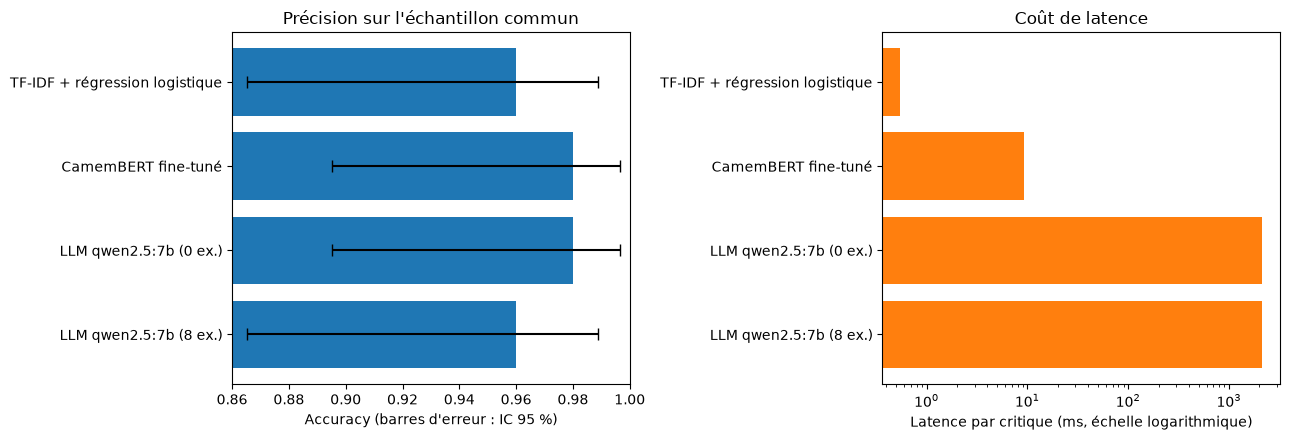

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

names = list(predictions)
stats = [score(predictions[n], labels) for n in names]
acc = np.array([s["accuracy"] for s in stats])
err_low = acc - np.array([s["ci_low"] for s in stats])
err_high = np.array([s["ci_high"] for s in stats]) - acc

axes[0].barh(names, acc, xerr=[err_low, err_high], color="tab:blue", capsize=4)
axes[0].set_xlabel("Accuracy (barres d'erreur : IC 95 %)")
axes[0].set_xlim(max(0.0, acc.min() - 0.1), 1.0)
axes[0].set_title("Précision sur l'échantillon commun")
axes[0].invert_yaxis()

latencies = []
for n in names:
    if n in llm_meta:
        latencies.append(llm_meta[n]["latency_ms"])
    elif n.startswith("TF-IDF"):
        latencies.append(meta[n].get("latency_ms", np.nan))
    else:
        latencies.append(meta[n].get("latency_ms_gpu", np.nan))

axes[1].barh(names, latencies, color="tab:orange")
axes[1].set_xscale("log")
axes[1].set_xlabel("Latence par critique (ms, échelle logarithmique)")
axes[1].set_title("Coût de latence")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

## 9. Les différences sont-elles réelles ?

Les intervalles de confiance se chevauchent souvent lorsque les précisions sont proches. Le test
de McNemar compare chaque paire d'approches sur les mêmes critiques. Une p-value inférieure à
0,05 indique que l'écart observé est peu probablement dû au hasard de l'échantillon.

Avec un échantillon de 1 000 critiques, seuls des écarts de plusieurs points sont détectables.
Une absence de significativité ne prouve donc pas que deux approches sont équivalentes : elle
signifie que l'échantillon ne permet pas de trancher.

In [17]:
correct = {name: np.asarray(pd.Series(p).fillna(-1).astype(int).values == labels) for name, p in predictions.items()}

pairs = []
for a, b in combinations(correct, 2):
    only_a, only_b, p_value = mcnemar_exact(correct[a], correct[b])
    pairs.append({
        "Approche A": a, "Approche B": b,
        "Seule A juste": only_a, "Seule B juste": only_b,
        "p-value": f"{p_value:.3f}",
        "Écart significatif (5 %)": "oui" if p_value < 0.05 else "non",
    })

pd.DataFrame(pairs)

,Approche A,Approche B,Seule A juste,Seule B juste,p-value,Écart significatif (5 %)
0,TF-IDF + régression logistique,CamemBERT fine-tuné,1,2,1.000,non
1,TF-IDF + régression logistique,LLM qwen2.5:7b (0 ex.),1,2,1.000,non
2,TF-IDF + régression logistique,LLM qwen2.5:7b (8 ex.),2,2,1.000,non
3,CamemBERT fine-tuné,LLM qwen2.5:7b (0 ex.),0,0,1.000,non
4,CamemBERT fine-tuné,LLM qwen2.5:7b (8 ex.),1,0,1.000,non
5,LLM qwen2.5:7b (0 ex.),LLM qwen2.5:7b (8 ex.),1,0,1.000,non


## 10. Critiques mal classées par toutes les approches

Lorsque des modèles très différents (un TF-IDF, un transformer, un LLM) se trompent tous sur la
même critique, la cause est rarement le modèle. Il s'agit plus souvent d'un label discutable,
d'une critique ambiguë ou ironique, ou d'un texte dont la note ne reflète pas le contenu. Ces
cas donnent une idée du plafond de précision réellement atteignable sur ce corpus.

In [18]:
all_wrong = ~np.any(np.vstack(list(correct.values())), axis=0)
print(f"{all_wrong.sum()} critique(s) sur {len(eval_df)} mal classée(s) par toutes les approches\n")

for _, row in eval_df[all_wrong].head(5).iterrows():
    truth = LABEL_WORDS[row["label"]]
    print(f"[Label du corpus : {truth}]")
    print(textwrap.fill(row["review"][:500], width=100))
    print("-" * 100)

0 critique(s) sur 50 mal classée(s) par toutes les approches



## 11. Sauvegarde

Les résultats du LLM et le tableau comparatif sont enregistrés. En mode test rapide, les
fichiers portent un suffixe distinct pour ne pas être confondus avec les résultats définitifs.

In [19]:
suffix = "_smoke_test" if SMOKE_TEST else ""
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "inconnu"

llm_results = []
for (model, k), run in llm_runs.items():
    s = score(run["pred"], run["label"])
    lm = llm_meta[f"LLM {model} ({k} ex.)"]
    llm_results.append({
        "model": model, "n_shots": k, "n_eval": N_EVAL,
        "accuracy": round(s["accuracy"], 4), "ci_low": round(s["ci_low"], 4), "ci_high": round(s["ci_high"], 4),
        "f1": round(s["f1"], 4), "parse_rate": round(s["parse_rate"], 4),
        "latency_ms_median": round(lm["latency_ms"], 1), "latency_ms_p95": round(lm["latency_p95_ms"], 1),
        "size_gb": round(lm["size_gb"], 2), "quantization": lm["quantization"],
        "num_ctx": NUM_CTX, "hardware": gpu_name, "smoke_test": SMOKE_TEST,
    })

(RESULTS_DIR / f"llm_ollama{suffix}.json").write_text(
    json.dumps(llm_results, ensure_ascii=False, indent=2), encoding="utf-8")
comparison.to_csv(RESULTS_DIR / f"comparison{suffix}.csv", index=False, encoding="utf-8")

print(f"Résultats enregistrés dans {RESULTS_DIR}/ (suffixe : '{suffix}')")

Résultats enregistrés dans results/ (suffixe : '_smoke_test')


## Synthèse

À compléter après l'exécution complète (`SMOKE_TEST = False`), en répondant aux questions
suivantes à partir du tableau et des tests ci-dessus :

1. **Précision** : quel est l'ordre des trois approches, et les écarts sont-ils significatifs ?
2. **Apport des exemples** : le prompt avec 8 exemples dépasse-t-il le prompt sans exemple ? Le
   cas échéant, l'apport justifie-t-il l'allongement du prompt et de la latence ?
3. **Fiabilité du format** : quel est le taux de réponses interprétables ? Un modèle local de
   petite taille qui ne respecte pas la consigne de format pose un problème pratique en
   production, indépendamment de sa précision.
4. **Coût** : à précision comparable, quelle approche est la plus légère à déployer ? Une
   baseline qui répond en une fraction de milliseconde sur CPU change le calcul par rapport à un
   LLM de plusieurs Go de mémoire vidéo.
5. **Interprétabilité** : la baseline expose les mots qui pèsent dans sa décision, ce que ni le
   transformer ni le LLM ne permettent aussi directement.
6. **Plafond** : les critiques mal classées par toutes les approches révèlent-elles des labels
   discutables ?
7. **Contamination possible** : Allociné est un corpus public, présent sur le web depuis des
   années. Un LLM peut en avoir vu des extraits pendant son pré-entraînement, ce qui pourrait
   gonfler artificiellement son score. Cette limite est à mentionner explicitement, et seule
   une évaluation sur des critiques inédites permettrait de l'écarter.

La conclusion attendue n'est pas forcément « le plus gros modèle gagne » : le bon choix dépend
du volume traité, de la latence acceptable, du matériel disponible et du besoin d'explicabilité.
